# 15. 기존 CNN 고장 유형 분류 검증
    **재학습 없이21개 클래스 출력을 독립적으로 평가한다.** 유형별 성능 → 올바른 진단 시각 → 가용성의 검출/진단 영향 순으로 읽는다.
    모델·threshold·라벨·분할은 기존값이다. Run All은 저장 결과만 읽으며 학습·모델선택을 하지 않는다.

In [1]:
from pathlib import Path
import json,pandas as pd,numpy as np
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/phase2.json').exists())
OUT=ROOT/'reports/fault_type_validation'
def table(name):return pd.read_csv(OUT/'tables'/name)
def show(df):display(df.style.hide(axis='index').format(precision=5,na_rep='미진단/해당없음'))
def image(name):display(Image(filename=str(OUT/'figures'/name)))
validation=json.loads((OUT/'validation.json').read_text())
assert validation['all_reference_results_match'] and validation['no_retraining'] and not validation['changed_files']

## 1. 정의가 다른 세 가지 분류 지표
    argmax21은Softmax최대, gated21은기존경보임계값적용, conditional20은실제고장구간을안다고가정한다.
    Accuracy와Macro F1은분모·결정규칙을함께읽는다. 출처: 기존동결CNN의전체유효Test확률.

mode,accuracy,macro_precision,macro_recall,macro_f1
argmax21,0.83107,0.87922,0.87669,0.87003
gated21,0.87325,0.86982,0.85287,0.85585
conditional20,0.91363,0.92357,0.91363,0.91153


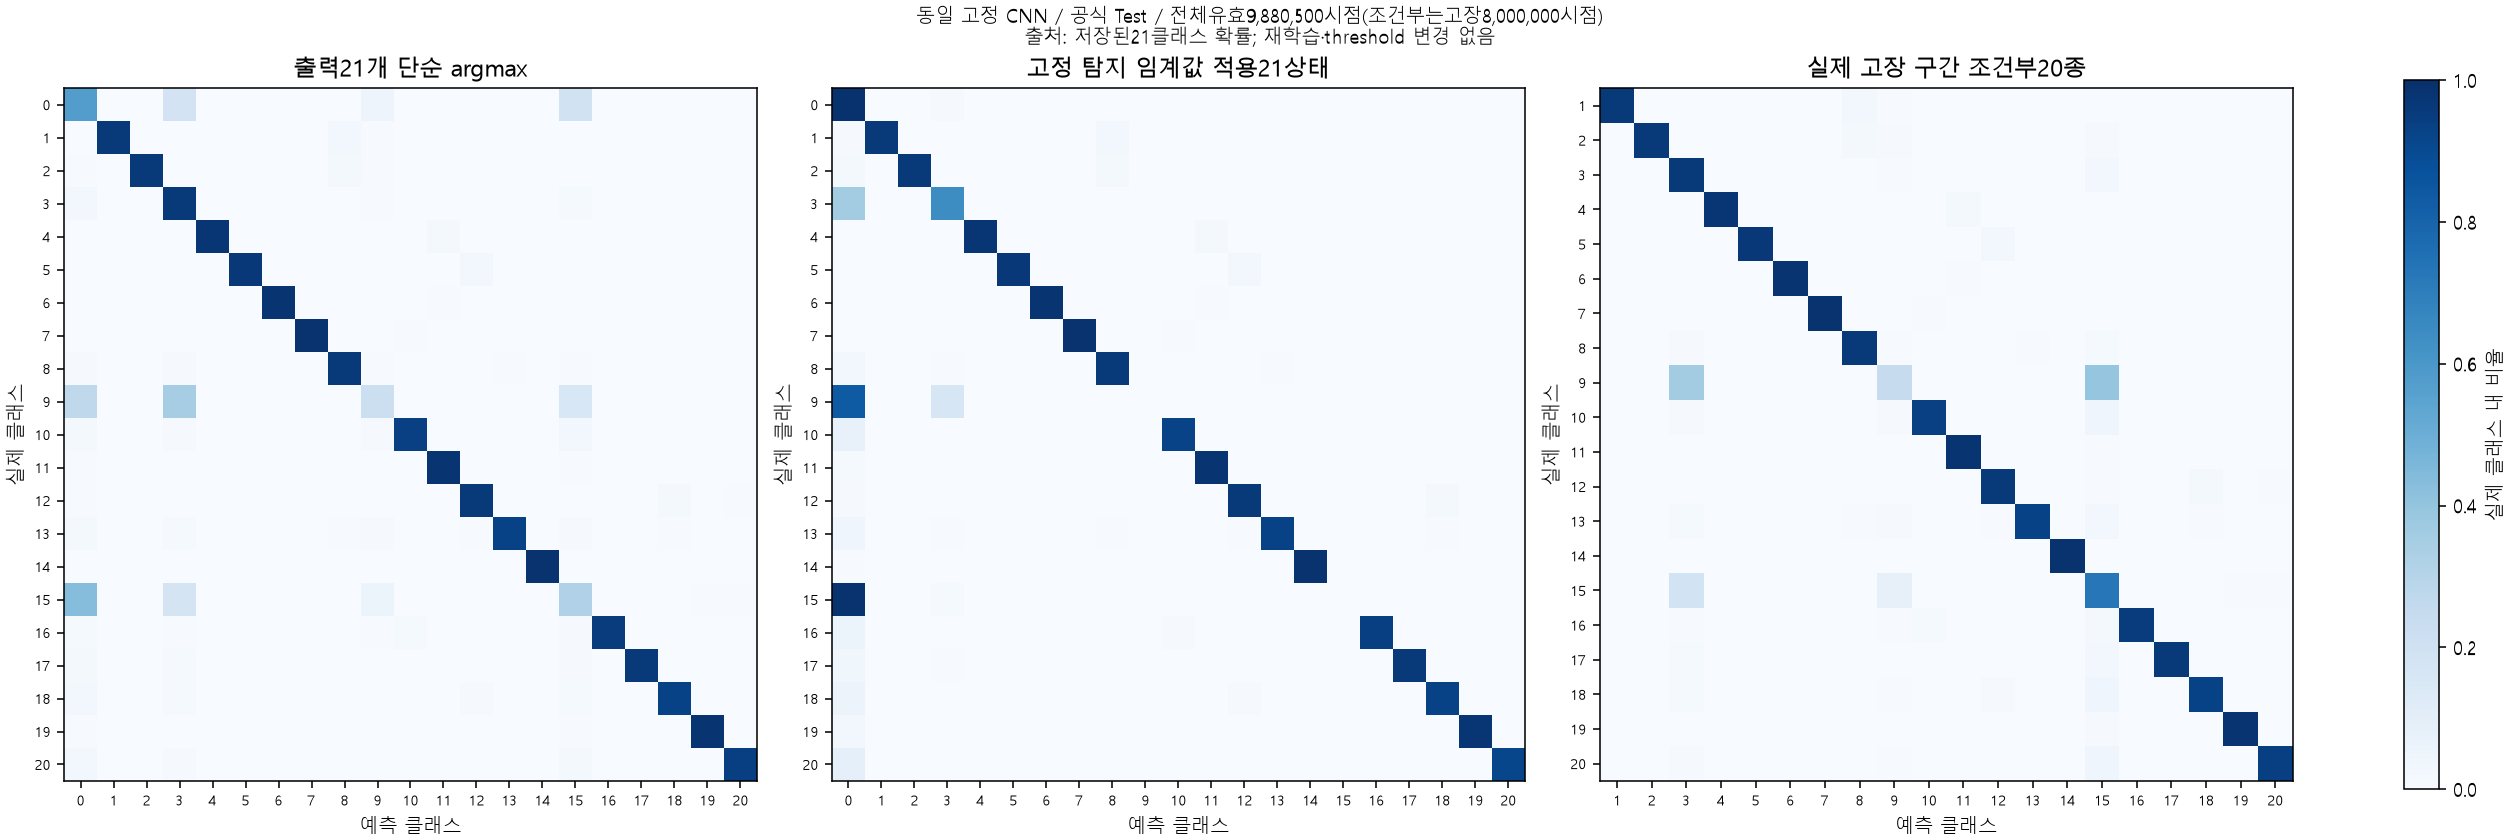

mode,class,precision,recall,f1,support
argmax21,0,0.75201,0.57225,0.64993,1880500
argmax21,1,0.99830,0.96064,0.97911,400000
argmax21,2,0.99952,0.96145,0.98012,400000
argmax21,3,0.39534,0.95722,0.55957,400000
argmax21,4,0.99786,0.97505,0.98632,400000
argmax21,5,0.99866,0.96484,0.98146,400000
argmax21,6,0.99976,0.98196,0.99078,400000
argmax21,7,0.99688,0.98816,0.99250,400000
argmax21,8,0.94913,0.95780,0.95345,400000
argmax21,9,0.37850,0.21724,0.27604,400000


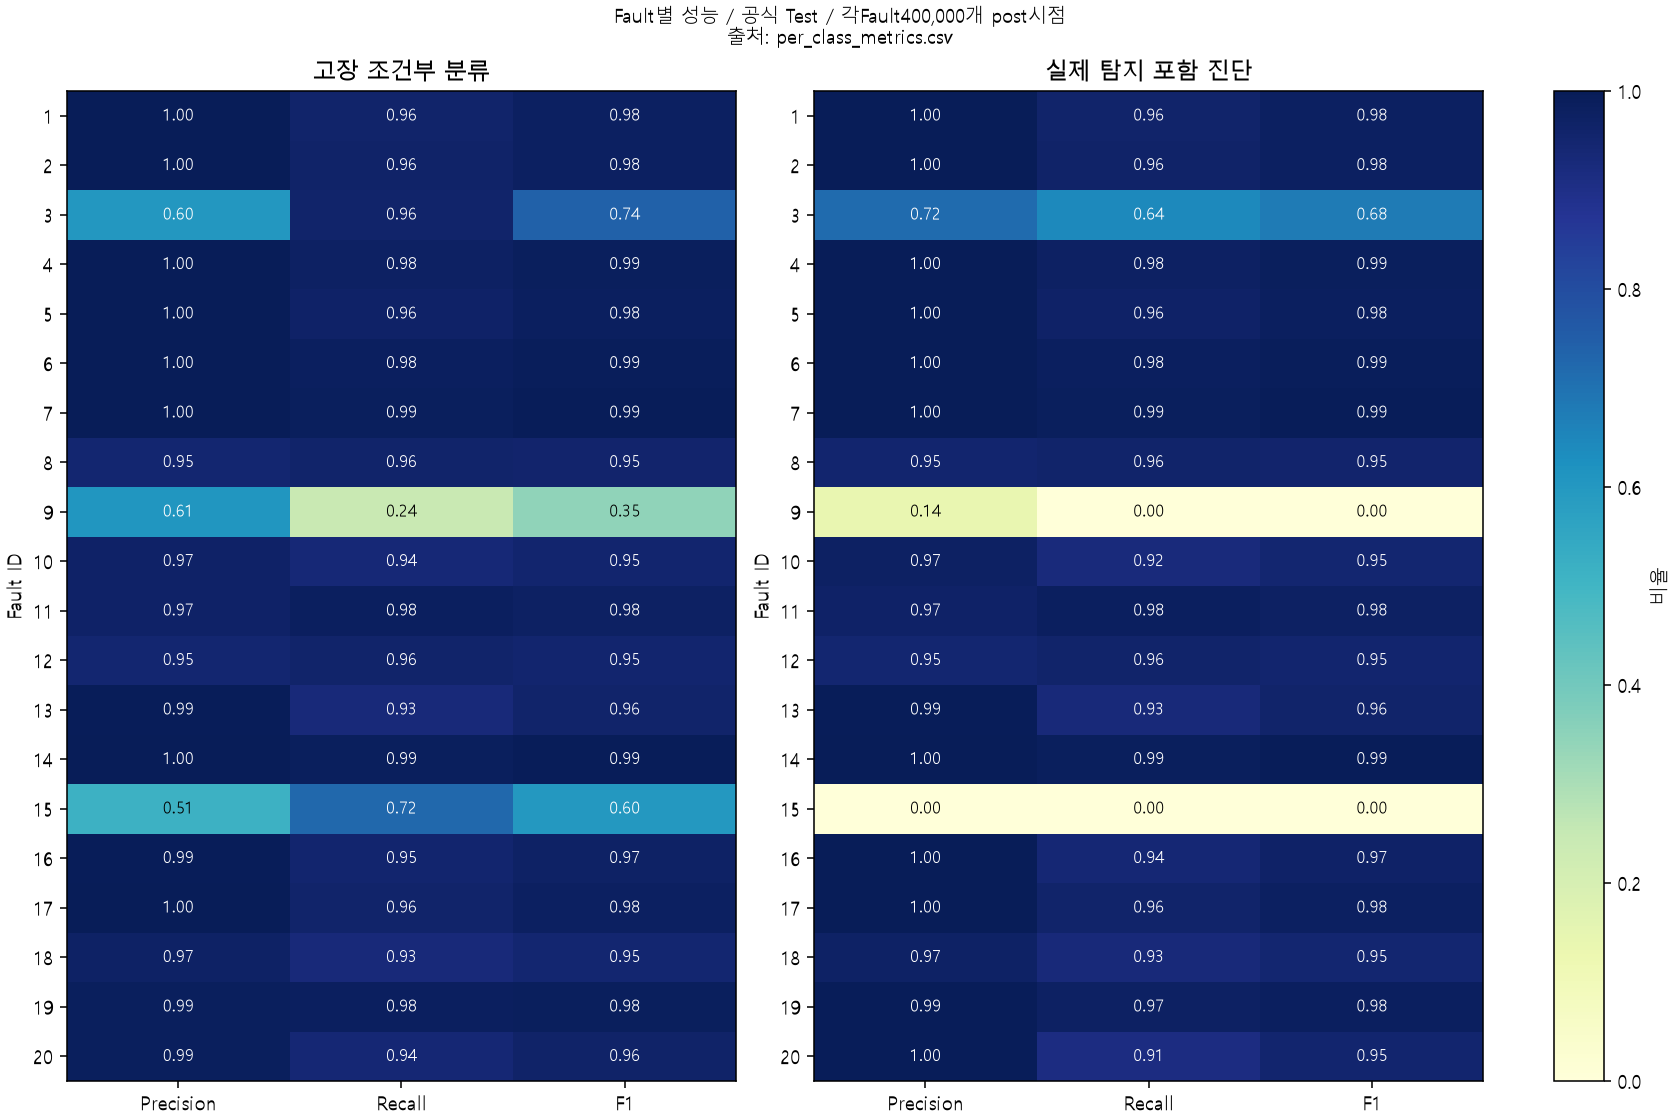

In [2]:
show(table('classification_summary.csv'))
image('confusions_three_definitions.png')
show(table('per_class_metrics.csv'))
image('per_fault_classification.png')

## 2. 어떤 고장으로 오분류하는가?
    정상0으로빠지는미탐과다른Fault로잘못판정하는오진을분리한다. 조건부후보가확률상높아도고장확률이낮으면경보가아니다.

In [3]:
pairs=table('confusion_pairs.csv')
show(pairs.groupby('mode',sort=False).head(8))
show(table('prediction_examples.csv'))

mode,actual,predicted,count,actual_class_fraction
argmax21,0,15,365080,0.19414
argmax21,0,3,338735,0.18013
argmax21,15,0,173141,0.43285
argmax21,9,3,139925,0.34981
argmax21,9,0,109125,0.27281
argmax21,0,9,91247,0.04852
argmax21,15,3,70492,0.17623
argmax21,9,15,61701,0.15425
conditional20,9,15,157961,0.39490
conditional20,9,3,142382,0.35596


actual,scenario,run,sample,fault_probability,conditional_candidate,gated_type,candidate_probability_given_fault,top3_types,interpretation
0,0,1,20,0.61427,15,0,0.55197,"15,9,18",conditional candidate is not a confirmed fault when gate fails
0,0,1,160,0.74669,15,0,0.46257,"15,9,3",conditional candidate is not a confirmed fault when gate fails
0,0,1,161,0.81257,3,0,0.37697,"3,15,9",conditional candidate is not a confirmed fault when gate fails
0,0,1,200,0.65419,15,0,0.46952,"15,9,18",conditional candidate is not a confirmed fault when gate fails
0,0,1,400,0.67387,15,0,0.61183,"15,9,18",conditional candidate is not a confirmed fault when gate fails
0,0,1,960,0.77018,9,0,0.33836,"9,15,3",conditional candidate is not a confirmed fault when gate fails
0,1,1,20,0.61427,15,0,0.55197,"15,9,18",conditional candidate is not a confirmed fault when gate fails
0,1,1,160,0.74669,15,0,0.46257,"15,9,3",conditional candidate is not a confirmed fault when gate fails
1,1,1,161,0.76030,15,0,0.38108,"15,3,9",conditional candidate is not a confirmed fault when gate fails
1,1,1,200,1.00000,1,1,0.99895,"1,8,18",conditional candidate is not a confirmed fault when gate fails


## 3. 검출과 올바른 유형 진단의 시간 차이
    탐지는3연속경보, 진단확정은같은양의예측ID3연속이다. 실제Fault는정답대조에만쓴다.
    첫유형판정정확도와40h내한번이라도올바르게진단한비율을구분한다. 지연은각사건성공실행에서만계산한다.

항목,결과
고장 실행,10000.00000
한번이라도 고장 검출,9851.00000
올바른 유형3연속 진단,9015.00000
최초 유형 확정 실행,9848.00000
최초 확정 유형이 정답,4417.00000
최초 유형 정확도(유형 확정 실행 분모),0.44852
올바른 진단 성공 실행 지연 중앙값(분),69.00000
검출~올바른 진단 추가 지연의 중앙값(분),12.00000


fault,runs,detected_runs,correct_diagnosis_runs,run_detection_rate,run_correct_diagnosis_rate,first_type_accuracy,detection_delay_median,correct_diagnosis_delay_median,additional_diagnosis_delay_median
1,500,500,500,1.00000,1.00000,0.00000,33.00000,105.00000,72.00000
2,500,500,500,1.00000,1.00000,0.00000,54.00000,102.00000,45.00000
3,500,500,500,1.00000,1.00000,0.99000,54.00000,54.00000,0.00000
4,500,500,500,1.00000,1.00000,0.00000,12.00000,69.00000,57.00000
5,500,500,500,1.00000,1.00000,0.00000,18.00000,93.00000,75.00000
6,500,500,500,1.00000,1.00000,0.00000,15.00000,51.00000,36.00000
7,500,500,500,1.00000,1.00000,0.13400,18.00000,30.00000,12.00000
8,500,500,500,1.00000,1.00000,0.40600,69.00000,84.00000,12.00000
9,500,500,15,1.00000,0.03000,0.00000,187.50000,1362.00000,906.00000
10,500,500,500,1.00000,1.00000,0.95800,87.00000,90.00000,0.00000


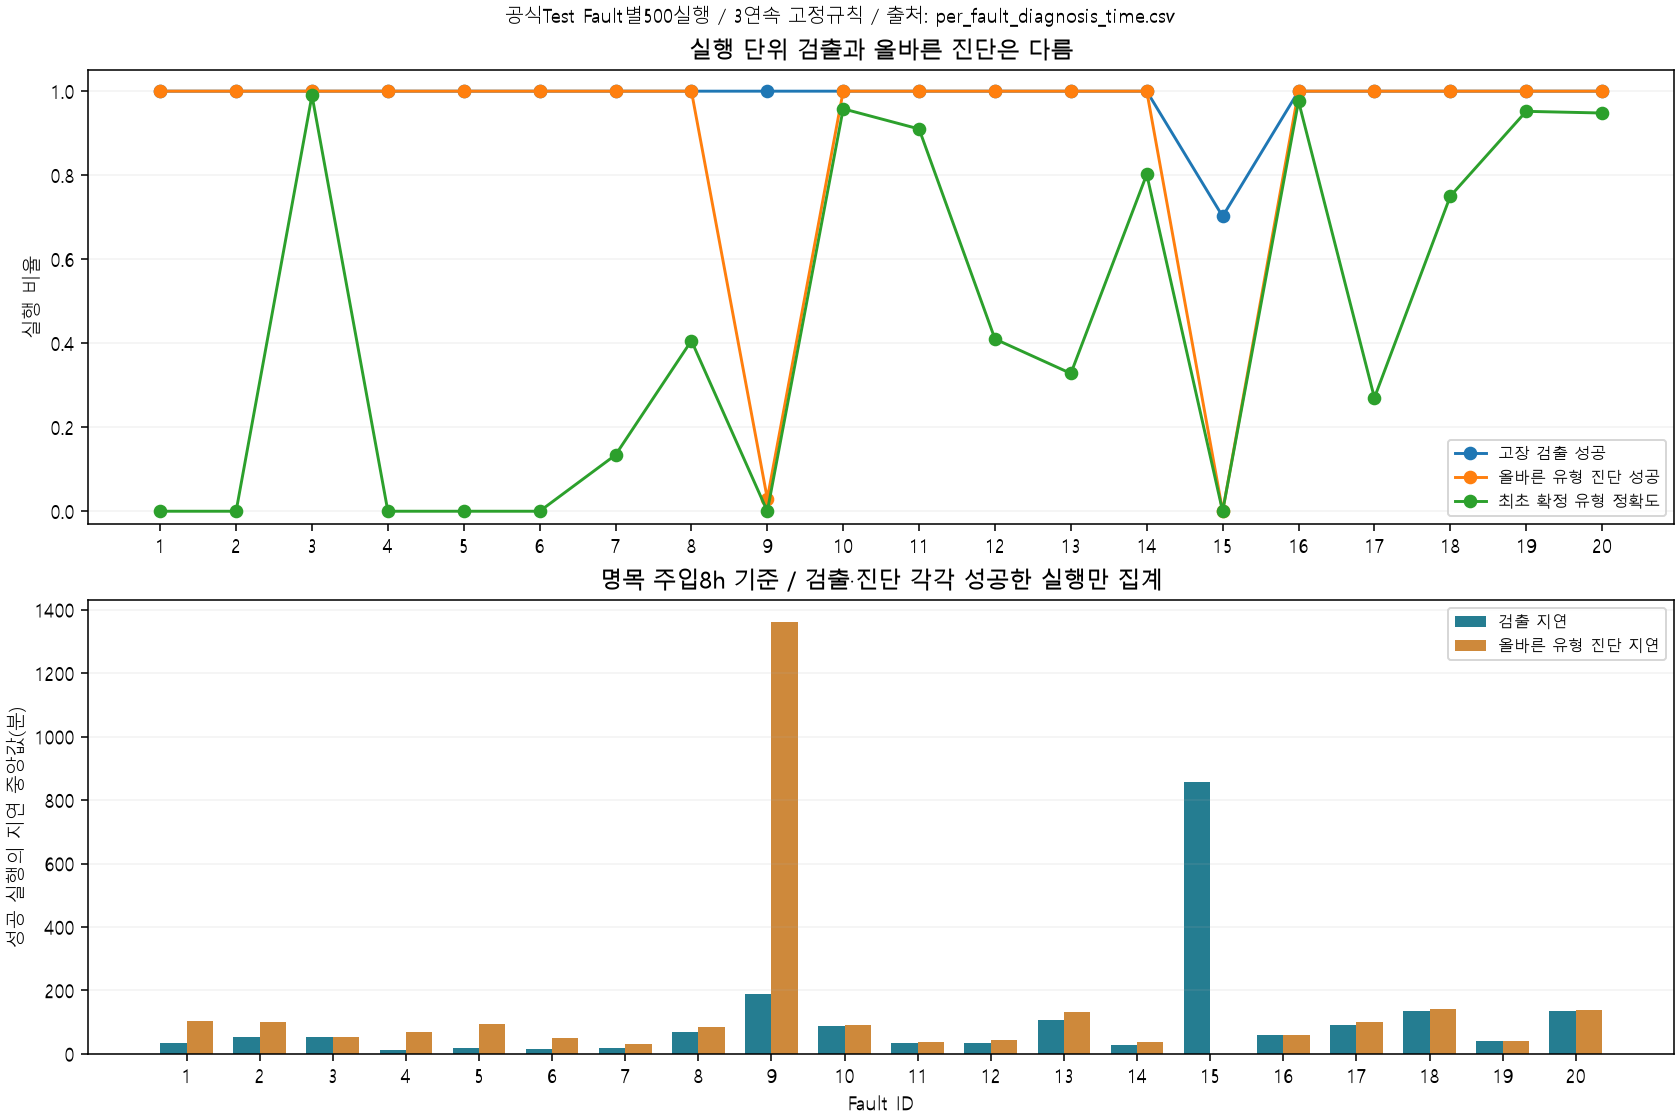

horizon_minutes,fault,runs,detection_rate_by_horizon,correct_diagnosis_rate_by_horizon
30,ALL,10000,0.33750,0.08430
60,ALL,10000,0.60700,0.36540
120,ALL,10000,0.80590,0.76730
240,ALL,10000,0.92840,0.88870


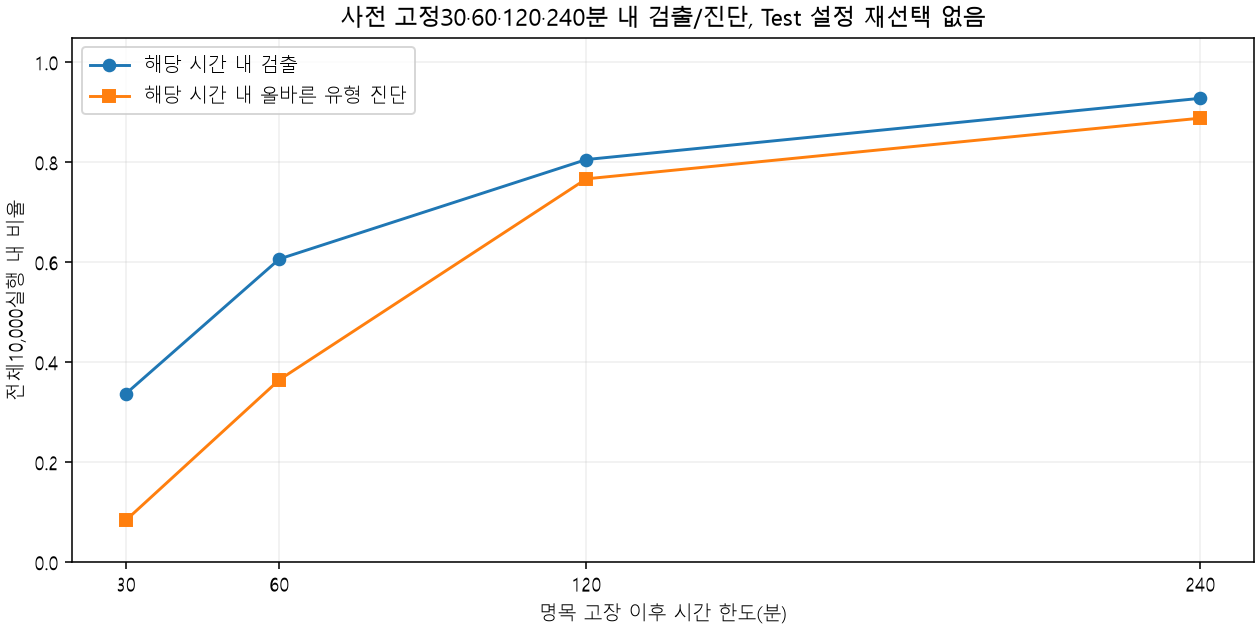

In [4]:
show(table('run_summary.csv'))
show(table('per_fault_diagnosis_time.csv'))
image('detection_vs_diagnosis_time.png')
show(table('early_diagnosis_horizons.csv').query('fault == "ALL"'))
image('early_correct_diagnosis.png')

## 4. 입력 가용성 저하가 검출·진단에 미치는 영향
    기존가용성실험과동일한5개비율×3개누락seed를재사용했다. CNN은같은seed42체크포인트다.
    전체실행과가용실행의분모를각각유지하며, 불가시점에정상/고장확률을만들지않는다.

rate,available_runs,overall_detection_rate,conditional_detection_rate,overall_correct_diagnosis_rate,conditional_correct_diagnosis_rate,conditional20_macro_f1,gated21_macro_f1
0.00000,10000.00000,0.98510,0.98510,0.90150,0.90150,0.91153,0.85585
0.10000,9000.00000,0.88640,0.98489,0.81140,0.90156,0.91165,0.85657
0.25000,7500.00000,0.73830,0.98440,0.67613,0.90151,0.91151,0.85754
0.40000,6000.00000,0.59067,0.98444,0.54093,0.90156,0.91156,0.85863
0.53100,4690.00000,0.46173,0.98451,0.42287,0.90163,0.91145,0.85943


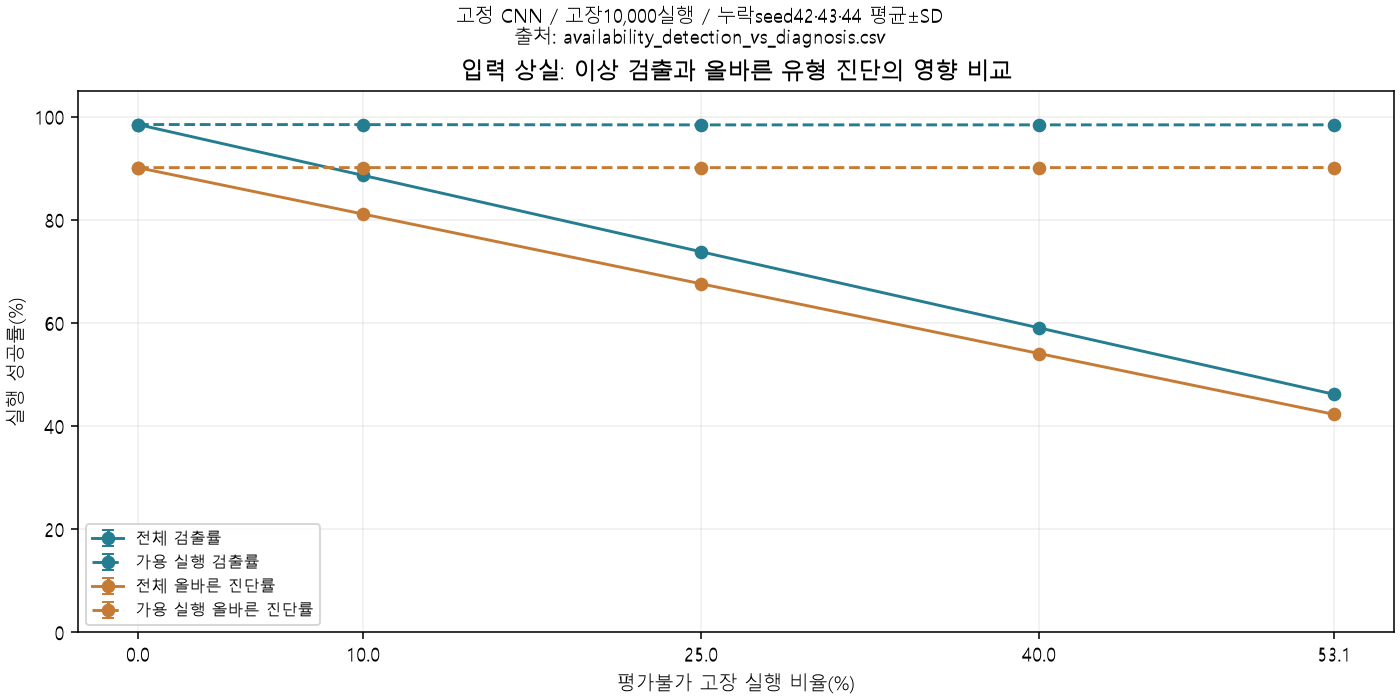

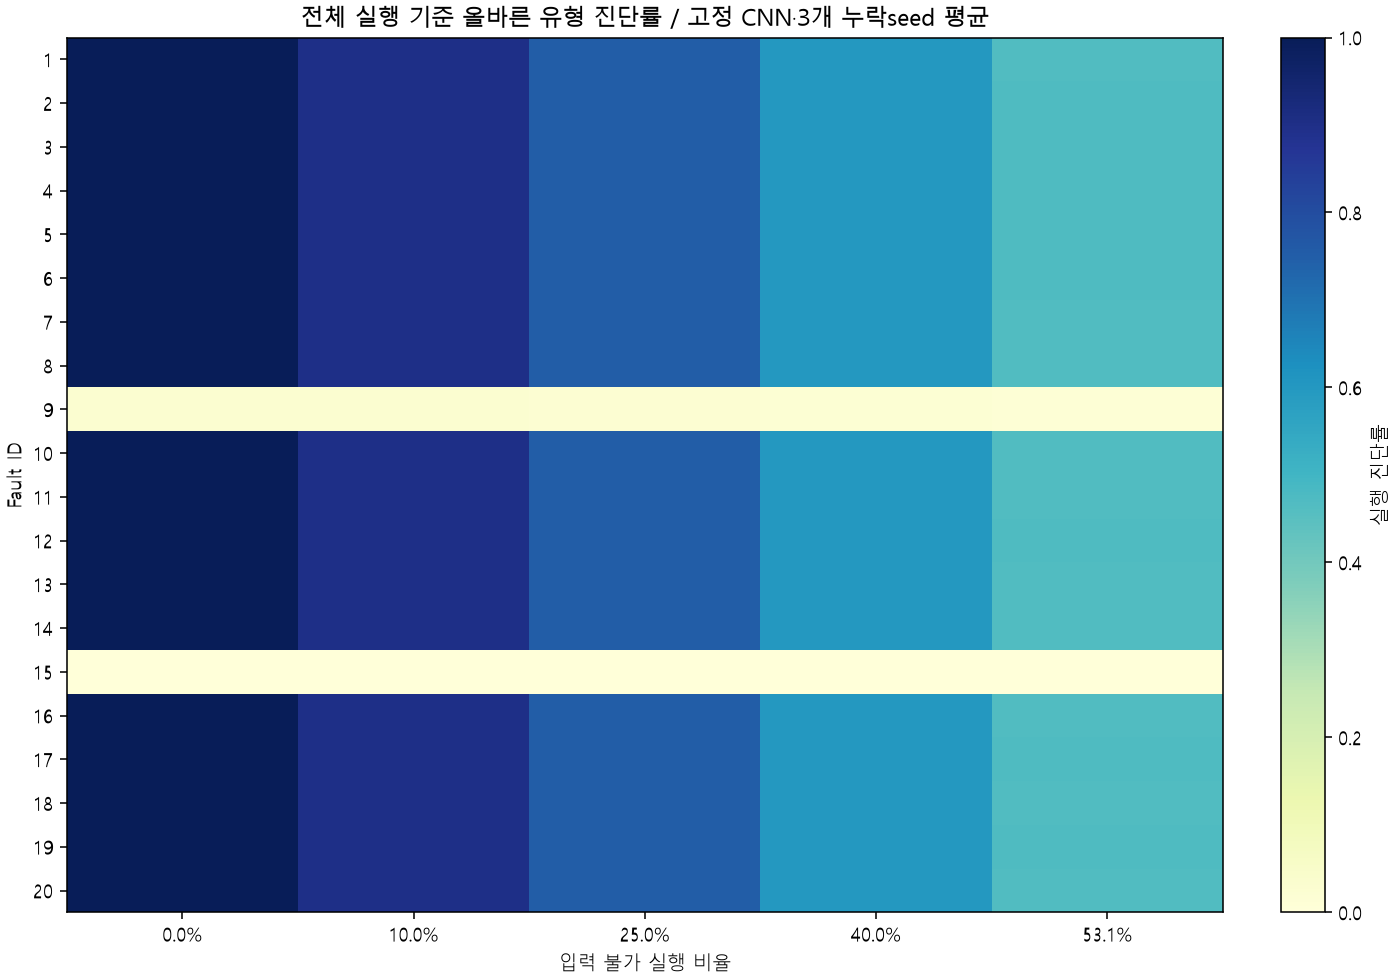

In [5]:
show(table('availability_mean.csv')[['rate','available_runs','overall_detection_rate','conditional_detection_rate','overall_correct_diagnosis_rate','conditional_correct_diagnosis_rate','conditional20_macro_f1','gated21_macro_f1']])
image('availability_detection_vs_diagnosis.png')
image('availability_per_fault_diagnosis.png')

## 5. 참고 저장소와 본 검증의 경계
    참고GitHub는LSTM다음시점예측과분류의2단계구조이며, 본검증은기존CNN을그대로사용한다. 클래스별지표와결과표시방식을참고했다.
    서로다른자료구성·시점·정상라벨·경보규칙이므로README점수로직접우열을정하지않는다.
    [참고저장소](https://github.com/min3237/tep-fault-diagnosis-dl). 물리원인적중률은미평가이며Fault16~20은UNKNOWN이다.

In [6]:
show(table('reference_comparison.csv'))
display(Markdown(f"고정모델: `{validation['model']}` · threshold={validation['threshold']:.6f} · 재학습없음 · 보호파일 {validation['unchanged_protected_files']}개 변경없음"))

항목,참고 GitHub README/설명,본 검증
구조,LSTM 다음시점 예측+실제9행/예측1행 분류,기존20×52 CNN의21출력을 그대로 평가
참고한 점,"클래스별 Precision/Recall/F1, 결과 표시",유형별 지표·혼동·시간·가용성 영향으로 확장
성능 직접 비교,자료 구성·시점·평가규칙이 다름,GitHub 수치와 모델 우열로 비교하지 않음
이번 고정 CNN 검증,새 forecaster를 CNN에 연결하지 않음,재학습·입력·가중치·threshold 변경 없음


고정모델: `CNN1D_Temporal_balanced_s42` · threshold=0.967192 · 재학습없음 · 보호파일 59개 변경없음